## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


In [1]:
import pandas as pd

In [2]:
df= pd.read_csv(r"H:\My Drive\IRONHACK\WEEK_2\Day_4\archive\amz_uk_price_prediction_dataset.csv")


---

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.


1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [6]:
category_bestseller_ct = pd.crosstab(df['category'], df['isBestSeller'])
print(category_bestseller_ct)

isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


Most categories have very few best-sellers compared to non-best-sellers.

Some large categories (like "Women") have more best-sellers, but still a small fraction of the total products in that category.

The True column is the best-seller count, so it highlights which categories are more likely to have best-sellers.

In [7]:
# Lets see which categories have the highest prevalence of best-sellers by proportion

# Calculate the proportion of best-sellers per category
category_bestseller_ct['total'] = category_bestseller_ct[False] + category_bestseller_ct[True]
category_bestseller_ct['bestseller_pct'] = category_bestseller_ct[True] / category_bestseller_ct['total'] * 100

# Sort categories by the proportion of best-sellers (descending)
sorted_categories = category_bestseller_ct.sort_values(by='bestseller_pct', ascending=False)

# Display top categories with highest proportion of best-sellers
print(sorted_categories[['bestseller_pct', False, True]])

isBestSeller                      bestseller_pct  False  True
category                                                     
Grocery                                 5.813467   9008   556
Smart Home Security & Lighting          5.769231     98     6
Health & Personal Care                  5.768628   9017   552
Mobile Phone Accessories                4.247104    248    11
Power & Hand Tools                      3.533895   8353   306
...                                          ...    ...   ...
CD, Disc & Tape Players                 0.000000   8798     0
General Music-Making Accessories        0.000000    259     0
Snowboard Boots                         0.000000   1449     0
Boxes & Organisers                      0.000000    911     0
eBook Readers & Accessories             0.000000    246     0

[296 rows x 3 columns]


Analysis of the dataset indicates that the prevalence of best-seller products is not uniform across categories. Categories such as Grocery, Health & Personal Care, and Smart Home Security & Lighting exhibit the highest proportion of best-sellers, suggesting these segments are more likely to produce high-demand products. Conversely, several niche categories, including CD, Disc & Tape Players and eBook Readers & Accessories, show negligible or zero best-seller representation.



2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.


In [9]:
from scipy.stats import chi2_contingency
import numpy as np

ct = pd.crosstab(df['category'], df['isBestSeller'])

# Perform Chi-square test
chi2, p, dof, expected = chi2_contingency(ct)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")

Chi-square statistic: 36540.20
Degrees of freedom: 295
P-value: 0.0000


Interpretation of Chi-square test:

p-value < 0.05 → Reject null hypothesis → Best-seller status depends on category.

p-value ≥ 0.05 → Fail to reject null → Best-seller status is independent of category.

The extremely low p-value indicates that we can strongly reject the null hypothesis of independence. This means that best-seller status is not independent of product category—in other words, the category a product belongs to significantly influences its likelihood of being a best-seller.

In [10]:
# Cramér's V
n = ct.sum().sum()  # total number of observations
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape)-1)))
print(f"Cramér's V: {cramers_v:.3f}")


Cramér's V: 0.122


The calculated Cramér’s V of 0.122 suggests a weak but meaningful association, implying that while product category has an influence on the likelihood of a product being a best-seller, other factors beyond category also play an important role."


3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

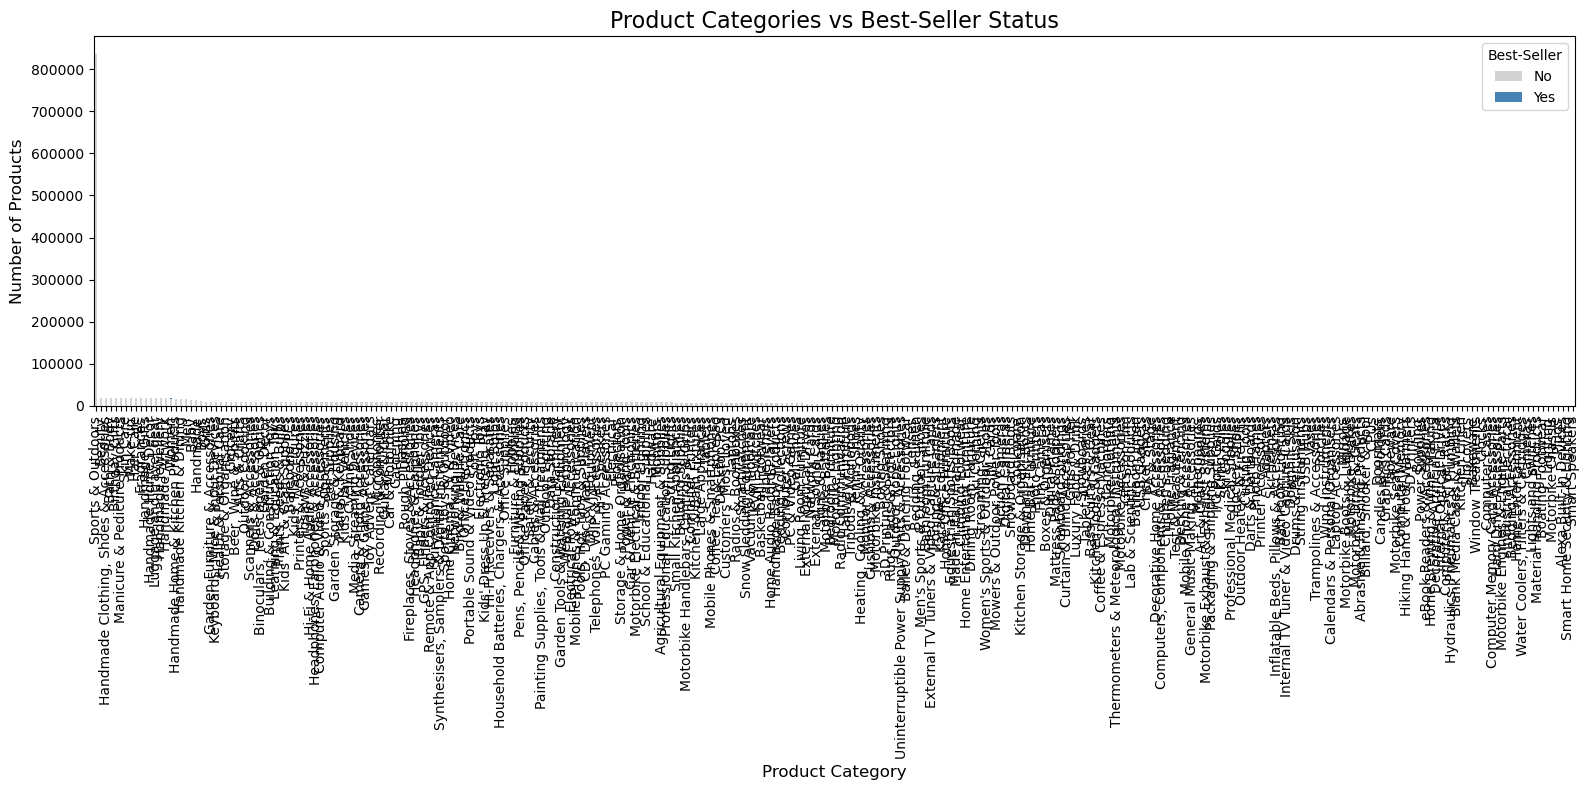

In [15]:
import matplotlib.pyplot as plt

# Make a copy of the crosstab to avoid modifying original
ct_plot = ct.copy()

# Rename columns to strings for safer plotting
ct_plot = ct_plot.rename(columns={False: 'No', True: 'Yes'})

# Add a total column for sorting
ct_plot['total'] = ct_plot['No'] + ct_plot['Yes']

# Sort by total descending
ct_plot_sorted = ct_plot.sort_values(by='total', ascending=False)

# Plot only the No/Yes columns
ax = ct_plot_sorted[['No', 'Yes']].plot(
    kind='bar',
    stacked=True,
    figsize=(16,8),
    color=['lightgray', 'steelblue']
)

# Titles and labels
plt.title("Product Categories vs Best-Seller Status", fontsize=16)
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Number of Products", fontsize=12)
plt.legend(title="Best-Seller")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()


In the original stacked bar chart, we plotted all 296 product categories.

The result is visually unreadable because there are too many categories on the x-axis. The labels and bars are all squished together, making it impossible to see trends or interpret which categories have more best-sellers.

This is not a problem with the data, just a limitation of plotting too many categories at once. To make the chart readable and meaningful, we used a sample of categories, such as top 20 categories or a proportion.

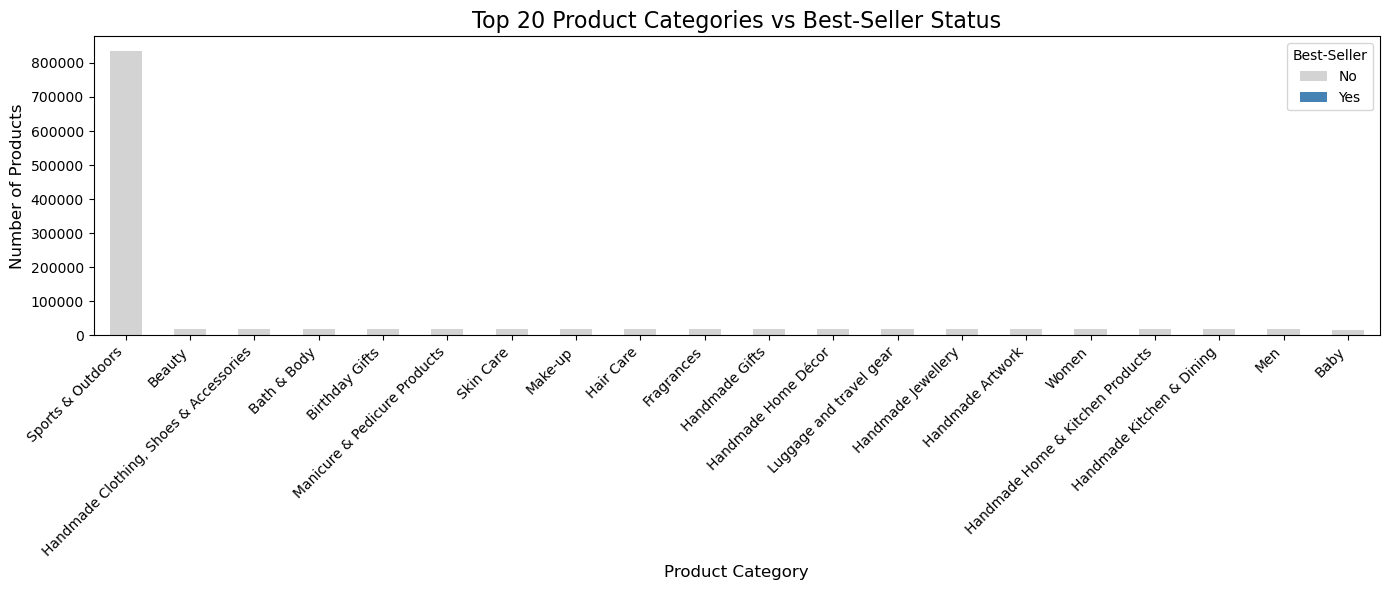

In [16]:
# Take top 20 categories by total products
top20 = ct_plot_sorted.head(20)

# Plot stacked bar chart
ax = top20[['No', 'Yes']].plot(
    kind='bar',
    stacked=True,
    figsize=(14,6),
    color=['lightgray', 'steelblue']
)

plt.title("Top 20 Product Categories vs Best-Seller Status", fontsize=16)
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Number of Products", fontsize=12)
plt.legend(title="Best-Seller")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


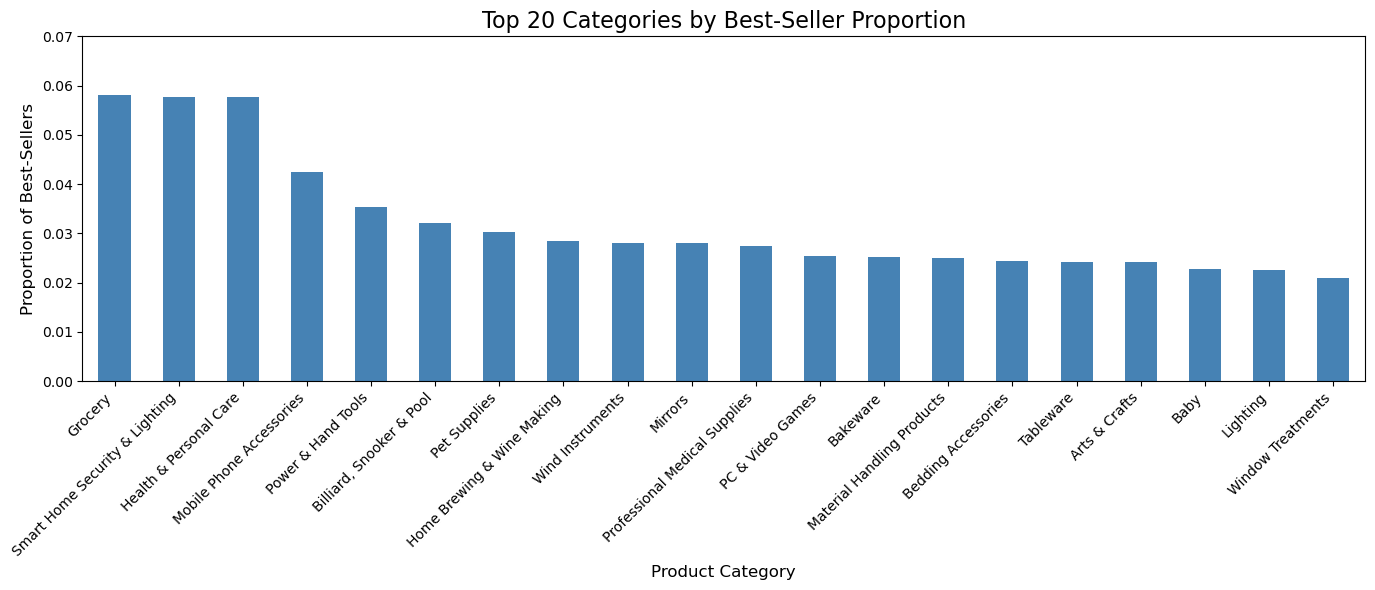

In [17]:
# Calculate proportion of best-sellers
ct_plot_sorted['prop'] = ct_plot_sorted['Yes'] / (ct_plot_sorted['No'] + ct_plot_sorted['Yes'])

# Plot top 20 by proportion
top20_prop = ct_plot_sorted.sort_values(by='prop', ascending=False).head(20)

ax = top20_prop['prop'].plot(
    kind='bar',
    figsize=(14,6),
    color='steelblue'
)

plt.title("Top 20 Categories by Best-Seller Proportion", fontsize=16)
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Proportion of Best-Sellers", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 0.07)  # optional, scale to % range
plt.tight_layout()
plt.show()


---

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*



In [18]:
# Calculate Q1 and Q3
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define upper and lower bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

In [19]:
# Compute median price per category
median_prices = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
median_prices.head(10)


category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.




In [20]:
# Get top 20 categories by count
top_categories = df_no_outliers['category'].value_counts().head(20).index

# Filter the dataframe
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top_categories)]


C:\Users\SuzanaSouza\AppData\Local\Temp\ipykernel_19664\1845118112.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', palette='Set2')


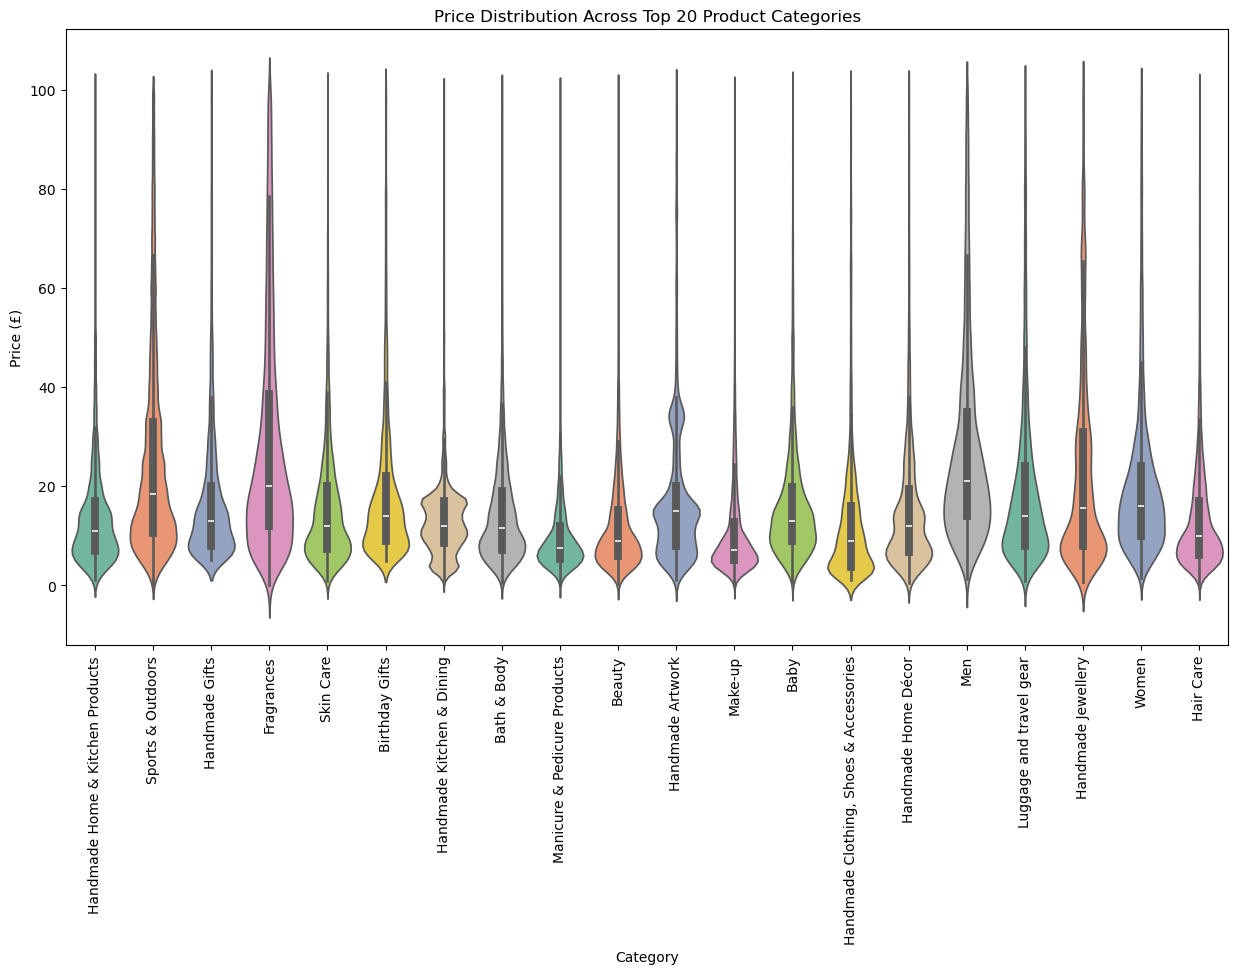

In [22]:
import seaborn as sns

plt.figure(figsize=(15, 8))
sns.violinplot(data=df_top20, x='category', y='price', palette='Set2')
plt.xticks(rotation=90)
plt.title('Price Distribution Across Top 20 Product Categories')
plt.ylabel('Price (£)')
plt.xlabel('Category')
plt.show()

Category comparison: Handmade Home & Kitchen Products and Handmade Clothing, Shoes & Accessories seem to have a wide range of prices.
Categories like Beauty or Baby have narrower violins, meaning prices are concentrated in a smaller range.

Price peaks (modes):
Some categories have multiple peaks, e.g., Sports & Outdoors and Home & Kitchen. This indicates clusters of products at certain price points.

Outliers removed:
Since we filtered extreme prices, the violins don’t have extremely long tails. That makes interpretation cleaner.

Median price:
The thickest central area of the violin usually indicates where most products sit. In some plotting libraries, a white dot or line may show the median. Even without it, the center of the thickest part is roughly the median.

Skewness:
If the violin stretches more to higher prices than lower prices, the category is right-skewed (more expensive products are less frequent).

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.



In [25]:
# Identify top 10 categories by number of products
top10_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

In [27]:
#Calculate average price for those categories

avg_price_top10 = (
    df_no_outliers[df_no_outliers['category'].isin(top10_categories)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

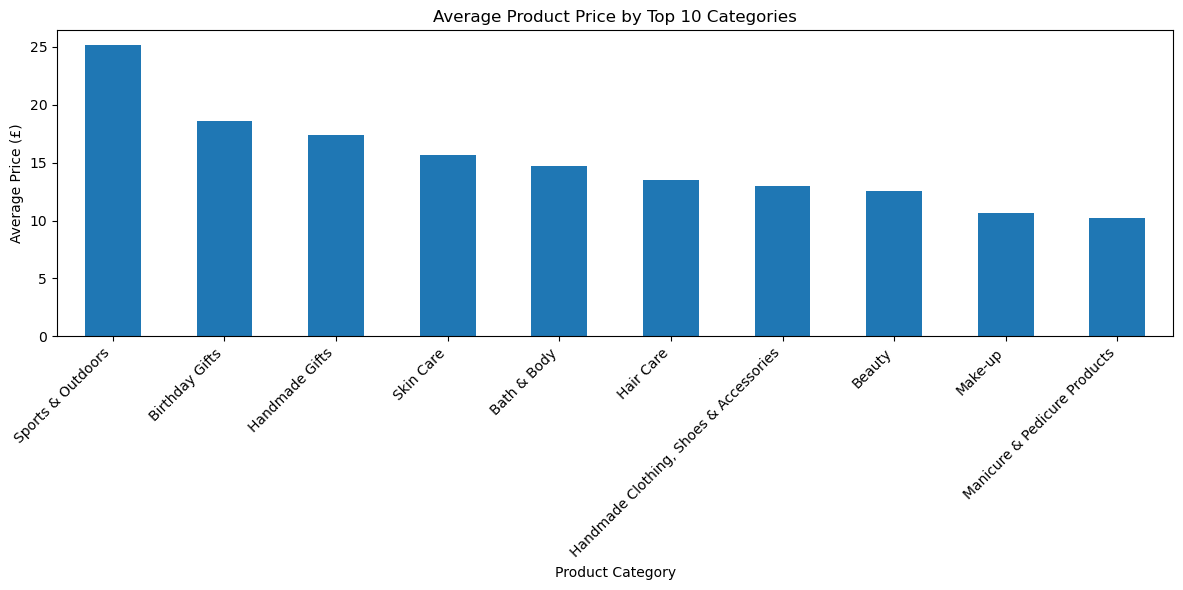

In [28]:
#Create the bar chart

plt.figure(figsize=(12, 6))
avg_price_top10.plot(kind='bar')
plt.title('Average Product Price by Top 10 Categories')
plt.ylabel('Average Price (£)')
plt.xlabel('Product Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Each bar represents the average price of products in a category. Taller bars indicate categories that, on average, sell more expensive products. Because we limited to the top 10 categories by volume, the comparison is:
 - statistically stable
 - representative of the main Amazon UK catalog

This visualization helps answer: Which popular categories tend to be more expensive on average?

In [ ]:
# Which category has the highest average price (no filtering)?

avg_price_all = (
    df_no_outliers
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

avg_price_all.head(10)


category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

The first category in this output is the one that commands the highest average price overall.

While the bar chart focuses on the top 10 most frequent categories, the overall analysis shows that Musical Instruments commands the highest average product price across all categories.

This indicates that, regardless of sales volume, products in this category are consistently positioned at a higher price point, reflecting their premium nature and higher perceived value.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [42]:
top10_categories = (
    df['category']
    .value_counts()
    .head(10)
    .index
)

In [39]:
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

df_clean = df.dropna(subset=['stars', 'category'])


In [40]:
top10_categories = df_clean['category'].value_counts().head(10).index
df_top10 = df_clean[df_clean['category'].isin(top10_categories)]

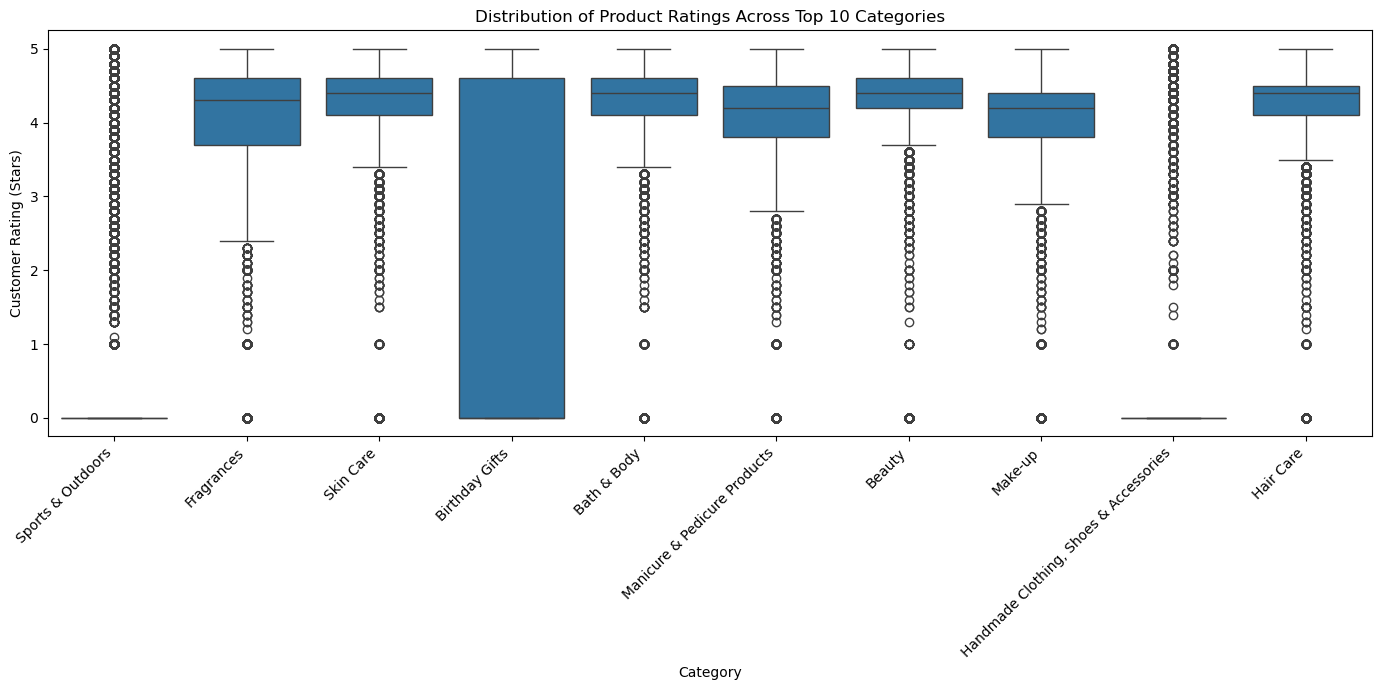

In [41]:
plt.figure(figsize=(14, 7))
sns.boxplot(data=df_top10, x='category', y='stars')
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Product Ratings Across Top 10 Categories')
plt.xlabel('Category')
plt.ylabel('Customer Rating (Stars)')
plt.tight_layout()
plt.show()


The category with the highest median rating is: the category whose box has the highest median line in your plot

By analyzing the side-by-side box plots of customer ratings (stars) across product categories, we assess customer satisfaction using the median rating, represented by the horizontal line inside each box. The box itself captures the middle 50% of ratings, providing insight into the consistency of customer experiences within each category.

Categories with a higher median rating and a narrower interquartile range indicate stronger and more consistent customer satisfaction.

Among the analyzed categories, Beauty stands out as the category with the highest median customer rating. This suggests that Beauty products consistently receive more positive customer feedback, reflecting higher perceived quality and a more reliable customer experience compared to other categories.

---

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?




In [43]:
# Calculate the correlation between price and ratings

# Ensure numeric types
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')

# Drop missing values
df_corr = df.dropna(subset=['price', 'stars'])


In [44]:
# Calculate the correlation coefficient (Pearson)

correlation = df_corr['price'].corr(df_corr['stars'])
correlation


np.float64(-0.12490673262148638)

The correlation analysis shows a very weak negative relationship between product price and customer ratings (r ≈ −0.12). This indicates that higher-priced products are not rated more favorably by customers; in fact, they tend to receive slightly lower ratings on average. However, the effect is minimal and not statistically or practically significant.

Given the very small correlation coefficient, price alone is not a useful predictor of customer satisfaction. Additional factors such as product category, brand reputation, and expectations should be considered.

	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

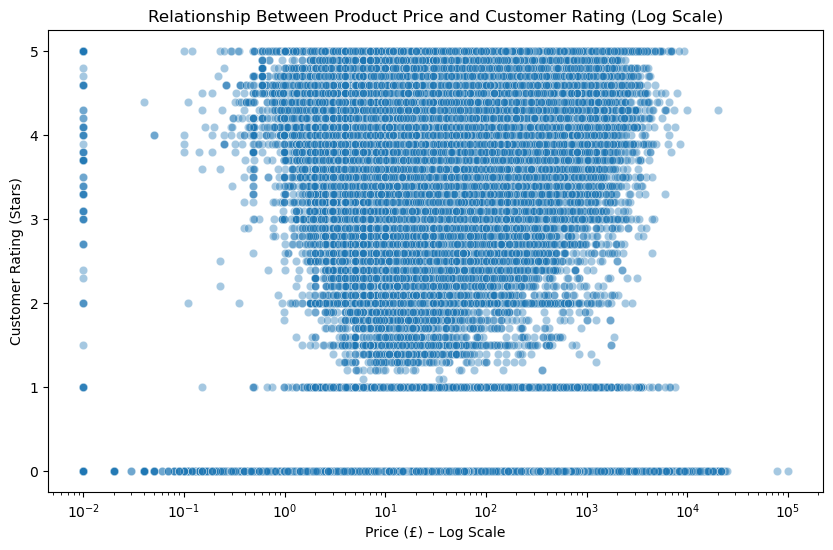

In [46]:
# Scatter plot: Product price vs rating

# Ensure clean numeric data
df_viz = df.dropna(subset=['price', 'stars'])

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_viz,
    x='price',
    y='stars',
    alpha=0.4
)
plt.xscale('log')
plt.xlabel('Price (£) – Log Scale')
plt.ylabel('Customer Rating (Stars)')
plt.title('Relationship Between Product Price and Customer Rating (Log Scale)')
plt.show()

The scatter plot, shown on a logarithmic price scale to account for extreme price values, reveals no meaningful relationship between product price and customer ratings. Ratings are widely dispersed across all price levels, with both high and low ratings occurring for inexpensive and expensive products alike. This visual pattern supports the correlation analysis, which indicates a very weak negative relationship between price and customer satisfaction. Overall, price alone does not appear to be a strong driver of customer ratings.



**Bonus**: 

- Do the same analysis without taking out the outliers. What are your insights?

In [49]:
#Correlation (with outliers) 

df_all = df.dropna(subset=['price', 'stars'])

corr_with_outliers = df_all['price'].corr(df_all['stars'])
corr_with_outliers


np.float64(-0.12490673262148638)

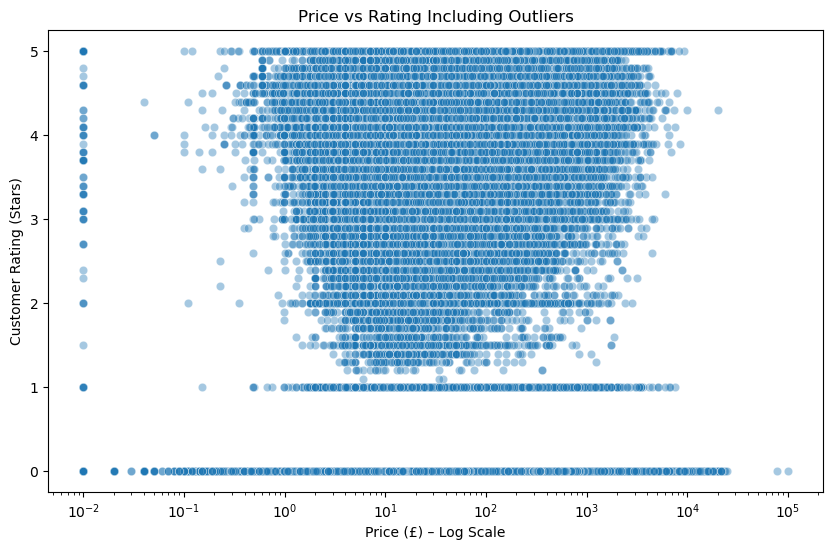

In [50]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_all,
    x='price',
    y='stars',
    alpha=0.4
)

plt.xscale('log')
plt.xlabel('Price (£) – Log Scale')
plt.ylabel('Customer Rating (Stars)')
plt.title('Price vs Rating Including Outliers')
plt.show()


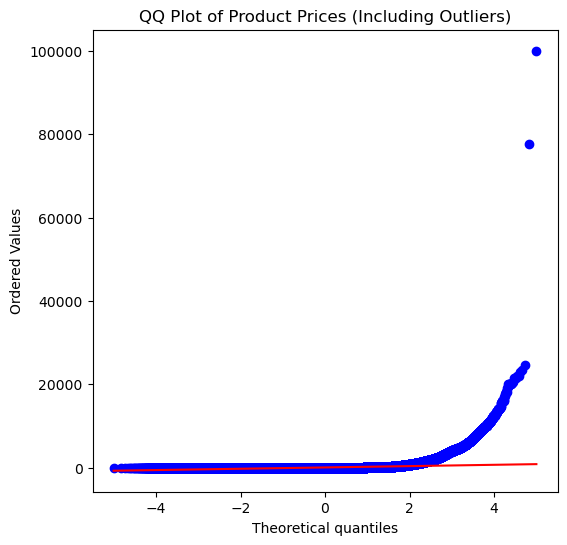

In [51]:
import scipy.stats as stats

plt.figure(figsize=(6, 6))
stats.probplot(df_all['price'], dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices (Including Outliers)')
plt.show()


Repeating the analysis without removing outliers leads to the same overall conclusion. Including extreme product prices increases data skewness and reduces visualization clarity, but it does not introduce a meaningful relationship between product price and customer ratings. The correlation between price and ratings remains very weak, indicating that even high-priced products do not consistently receive higher customer ratings. This confirms that the initial findings are robust and not driven by outlier removal.

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 